# Day 06 · 项目反应理论（一）：题目并不等价

**心理大模型评测与 Agent** · 评测方法学 · 建议用时 3 到 4 小时

**今天的目标**

- 写出 Rasch、2PL、3PL 模型并解释参数
- 画出项目特征曲线和信息曲线，并解释峰值位置
- 说明边际极大似然加 EM 的思路
- 把 IRT 用到“模型 × 临床情景”数据上，并认识样本量的限制

**怎么用这个 notebook**：先看同一文件夹里的 `slides.html`，再从上到下运行这里的单元格。标着 **练习** 的单元格需要你自己填写，填完运行下面的批改单元格，会显示 `正确`、`再想想` 或 `待完成`。所有数据都是课程编写或模拟的，没有真实来访者数据。

In [1]:
# 课程环境设置:让 notebook 找到课程代码库 src/course
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "course").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from course.plotting import use_style, OCHRE, TEAL, ROSE, SAND, INK
from course.check import check, check_true, summary
use_style()
pd.set_option("display.precision", 3)

## 1. 模拟“模型 × 临床情景”数据

60 个模型（或模型配置），40 道临床情景题。1 表示回复满足该题的评分标准。真实参数已知，方便检验估计是否准确。

In [2]:
from course.data import simulate_vignette_matrix
from course.irt import fit_2pl, item_information, total_information
u, theta, a_true, b_true, items = simulate_vignette_matrix(n_models=60, n_items=40, seed=0)
items.head(8)

,item,skill,a_true,b_true
0,V01,risk triage,0.877,0.503
1,V02,validation,0.704,0.990
2,V03,guided discovery,1.685,-0.164
3,V04,behavioural activation,0.862,-1.074
4,V05,scope of practice,1.104,0.873
5,V06,psychoeducation accuracy,0.925,-1.280
6,V07,older-adult tailoring,1.608,-0.713
7,V08,cultural fit,1.486,0.621


收敛: True  迭代: 40


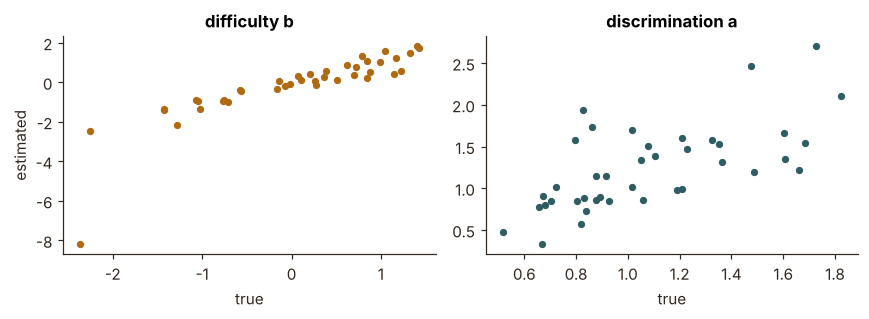

corr b: 0.844  corr a: 0.663


In [3]:
fit = fit_2pl(u)
print("收敛:", fit["converged"], " 迭代:", fit["n_iter"])
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].scatter(b_true, fit["b"], color=OCHRE, s=14); ax[0].set_title("difficulty b"); ax[0].set_xlabel("true"); ax[0].set_ylabel("estimated")
ax[1].scatter(a_true, fit["a"], color=TEAL, s=14); ax[1].set_title("discrimination a"); ax[1].set_xlabel("true")
plt.tight_layout(); plt.show()
print("corr b:", round(np.corrcoef(fit['b'], b_true)[0,1], 3), " corr a:", round(np.corrcoef(fit['a'], a_true)[0,1], 3))

**练习 6.1**：区分度 a = 1.6 的题，在 θ = b 处的信息量是多少？（提示：P = 0.5)

In [4]:
ans_6_1 = None
check("练习 6.1 最大信息量", ans_6_1, 1.6**2 / 4, tol=1e-6)

[ 待完成 ] 练习 6.1 最大信息量


**练习 6.2**：用估计出的参数，找出在 θ = 1（强模型区间）上信息量最大的题，填它的下标（0 开始）。

In [5]:
ans_6_2 = None
check("练习 6.2 θ=1 处信息量最大的题", ans_6_2, int(item_information(1.0, fit["a"], fit["b"])[0].argmax()))

[ 待完成 ] 练习 6.2 θ=1 处信息量最大的题


## 2. 用在人类量表上：PHQ-9 风格数据

把每题“≥ 2 分”（一半以上天数）视为认可该症状，拟合 2PL。模拟中第 2 题（情绪低落）的载荷最高。

In [6]:
from course.data import simulate_phq9
t1, _, latent = simulate_phq9(n=1500, seed=2)
endorse = (t1 >= 2).astype(float)
phq_fit = fit_2pl(endorse)
pd.DataFrame({"item": [f"PHQ{j+1}" for j in range(9)], "a": phq_fit["a"], "b": phq_fit["b"],
              "endorse_rate": endorse.mean(0)})

,item,a,b,endorse_rate
0,PHQ1,2.497,0.914,0.229
1,PHQ2,2.835,0.814,0.247
2,PHQ3,1.680,1.315,0.180
3,PHQ4,1.888,1.143,0.201
4,PHQ5,1.624,1.326,0.182
5,PHQ6,2.361,1.044,0.202
6,PHQ7,1.707,1.262,0.188
7,PHQ8,1.408,1.502,0.171
8,PHQ9,1.551,1.324,0.188


**练习 6.3**：哪一题的区分度最高？填下标（0 开始）。

In [7]:
ans_6_3 = None
check("练习 6.3 区分度最高的 PHQ 题", ans_6_3, int(np.argmax(phq_fit["a"])))

[ 待完成 ] 练习 6.3 区分度最高的 PHQ 题


## 3. 被试太少时会发生什么

只用 40 个模型重复拟合，比较区分度估计的质量。

In [8]:
from course.irt import simulate_2pl
rows = []
for n in [40, 400]:
    for rep in range(3):
        uu, th, aa, bb = simulate_2pl(n, 30, seed=100 + rep)
        ff = fit_2pl(uu, max_iter=80)
        rows.append({"n_models": n, "corr_a": np.corrcoef(ff["a"], aa)[0, 1], "corr_b": np.corrcoef(ff["b"], bb)[0, 1]})
small = pd.DataFrame(rows).groupby("n_models").mean(); small

,corr_a,corr_b
n_models,,
40,0.534,0.899
400,0.881,0.973


**练习 6.4**：在 40 个模型时，难度和区分度哪个估计得更好？填 `"a"` 或 `"b"`。

In [9]:
ans_6_4 = None
check("练习 6.4", ans_6_4, "b" if small.loc[40, "corr_b"] > small.loc[40, "corr_a"] else "a")

[ 待完成 ] 练习 6.4


## 口述题（录音，每题 90 秒）

1. 为什么所有模型都能答对的题应该考虑删掉？
   <details><summary>参考要点</summary>它的信息量集中在很低的能力区间，对区分当前模型几乎没有贡献，只增加成本。但如果它测的是安全底线，可以保留作为门槛题，不计入排序。</details>
2. 只有 8 个模型，能用 2PL 吗？
   <details><summary>参考要点</summary>不能。区分度估计不稳。可以用 Rasch 或描述性题目分析，或者用公开的多模型逐题数据估计题目参数，再用到自己的模型上。</details>

## 研究延伸

把 IRT 用在心理健康评测集上，可以回答“哪些临床情景最能区分模型”。例如：间接表达的风险、老年人特有的担忧，是否是高区分度的题？这需要足够多的模型或模型配置，可以通过同一模型的不同系统提示来扩充被试。

In [10]:
summary()

本 notebook 自动批改:0 / 4 通过
